# Step 2: Explore the data (BRFSS 2023 + 2024)

**Question:** Is memory loss only about age?

About 208,000 adults aged 45+ answered: *"During the past 12 months, have you experienced
confusion or memory loss that is happening more often or is getting worse?"*

All percentages are **weighted** with the survey weights, so they represent the US population
in the states that asked the question. Only group totals are shown.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(ROOT / "data" / "processed" / "brfss_2023_2024.csv")
df["band"] = df["age_band"].map({"45-64": "Younger (45-64)", "65+": "Older (65+)"})

YOUNG, OLD, INK, MUTED = "#2A5C8A", "#B4532A", "#1E2A44", "#6B7280"
COLORS = {"Younger (45-64)": YOUNG, "Older (65+)": OLD}
MIN_GROUP = 50  # hide groups with fewer people

plt.rcParams.update({
    "figure.dpi": 110, "font.size": 11, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#C9CDD4", "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.titleweight": "bold", "axes.titlesize": 13, "axes.titlecolor": INK,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#ECEEF1", "axes.axisbelow": True,
})

def wsummary(data, by, col="memory_loss"):
    """People and weighted % with memory loss per group. Small groups hidden."""
    d = data.dropna(subset=[col] + by)
    t = d.groupby(by, observed=True).apply(
        lambda g: pd.Series({"people": len(g), "pct": 100 * np.average(g[col], weights=g["weight"])}),
        include_groups=False)
    t["pct"] = t["pct"].round(1)
    t["people"] = t["people"].astype(int)
    return t[t["people"] >= MIN_GROUP].reset_index()

def save(fig, name):
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight", facecolor="white")

print(f"People: {len(df):,} | states: {df['state'].nunique()} | years: 2023-2024")

People: 208,171 | states: 37 | years: 2023-2024


## 1. Memory loss by age

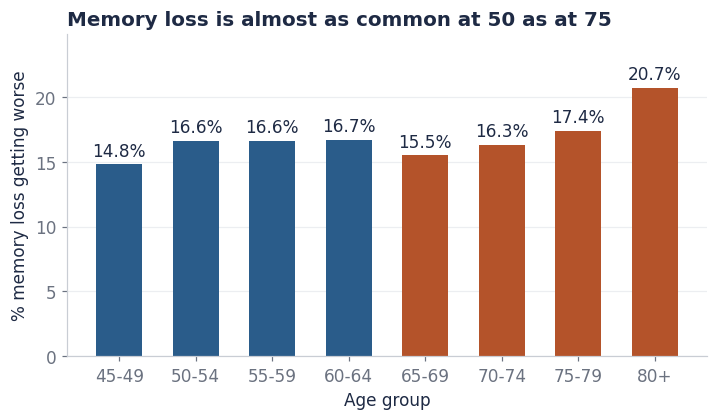

,age_group,people,pct
0,45-49,18966,14.8
1,50-54,21548,16.6
2,55-59,23485,16.6
3,60-64,29102,16.7
4,65-69,32659,15.5
5,70-74,30865,16.3
6,75-79,24396,17.4
7,80+,27150,20.7


In [2]:
by_age = wsummary(df, ["age_group"])
fig, ax = plt.subplots(figsize=(7.5, 3.8))
colors = [YOUNG if g in ("45-49", "50-54", "55-59", "60-64") else OLD for g in by_age["age_group"]]
bars = ax.bar(by_age["age_group"], by_age["pct"], color=colors, width=0.6)
ax.bar_label(bars, labels=[f"{p}%" for p in by_age["pct"]], padding=3, color=INK)
ax.set_title("Memory loss is almost as common at 50 as at 75", loc="left")
ax.set_xlabel("Age group"); ax.set_ylabel("% memory loss getting worse")
ax.set_ylim(0, by_age["pct"].max() * 1.2)
save(fig, "01_memory_by_age"); plt.show()
by_age

## 2. Income: younger vs older

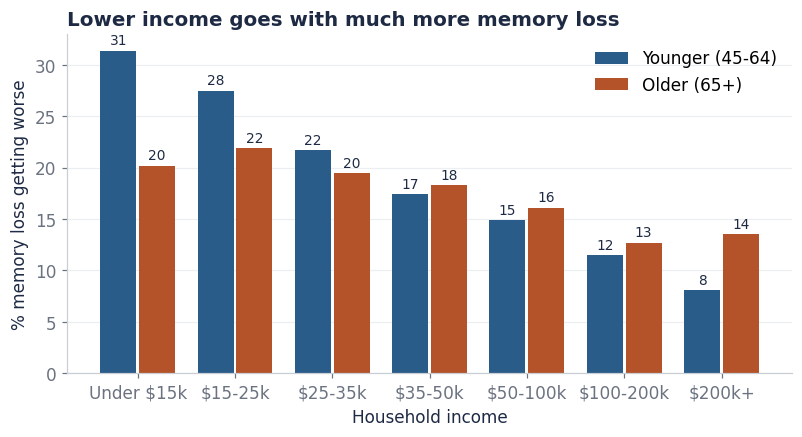

band,Older (65+),Younger (45-64)
income,,
1 Under $15k,20.2,31.4
2 $15-25k,21.9,27.5
3 $25-35k,19.5,21.7
4 $35-50k,18.3,17.4
5 $50-100k,16.1,14.9
6 $100-200k,12.7,11.5
7 $200k+,13.5,8.1


In [3]:
order = ["1 Under $15k", "2 $15-25k", "3 $25-35k", "4 $35-50k", "5 $50-100k", "6 $100-200k", "7 $200k+"]
by_inc = wsummary(df, ["band", "income"])
fig, ax = plt.subplots(figsize=(8.5, 4))
x = np.arange(len(order)); w = 0.4
for i, (band, color) in enumerate(COLORS.items()):
    d = by_inc[by_inc["band"] == band].set_index("income").reindex(order)
    bars = ax.bar(x + (i - 0.5) * w, d["pct"], width=w - 0.03, color=color, label=band)
    ax.bar_label(bars, labels=[f"{p:.0f}" for p in d["pct"]], padding=2, fontsize=9, color=INK)
ax.set_xticks(x, [o[2:] for o in order])
ax.set_xlabel("Household income"); ax.set_ylabel("% memory loss getting worse")
ax.set_title("Lower income goes with much more memory loss", loc="left")
ax.legend(frameon=False)
save(fig, "02_memory_by_income"); plt.show()
by_inc.pivot(index="income", columns="band", values="pct").reindex(order)

## 3. Education: younger vs older

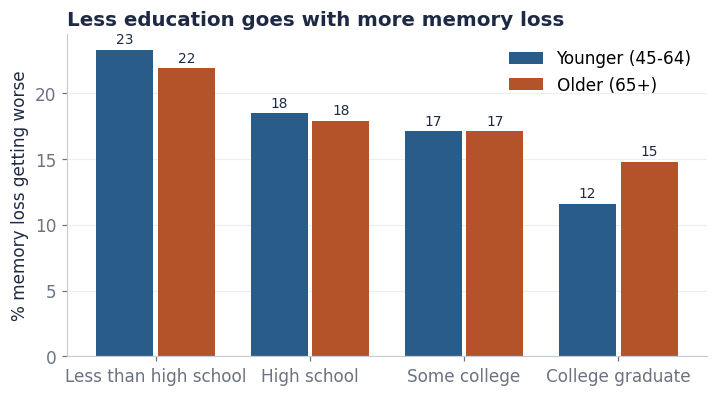

band,Older (65+),Younger (45-64)
education,,
1 Less than high school,21.9,23.3
2 High school,17.9,18.5
3 Some college,17.1,17.1
4 College graduate,14.8,11.6


In [4]:
eorder = ["1 Less than high school", "2 High school", "3 Some college", "4 College graduate"]
by_edu = wsummary(df, ["band", "education"])
fig, ax = plt.subplots(figsize=(7.5, 3.8))
x = np.arange(len(eorder)); w = 0.4
for i, (band, color) in enumerate(COLORS.items()):
    d = by_edu[by_edu["band"] == band].set_index("education").reindex(eorder)
    bars = ax.bar(x + (i - 0.5) * w, d["pct"], width=w - 0.03, color=color, label=band)
    ax.bar_label(bars, labels=[f"{p:.0f}" for p in d["pct"]], padding=2, fontsize=9, color=INK)
ax.set_xticks(x, [e[2:] for e in eorder])
ax.set_ylabel("% memory loss getting worse")
ax.set_title("Less education goes with more memory loss", loc="left")
ax.legend(frameon=False)
save(fig, "03_memory_by_education"); plt.show()
by_edu.pivot(index="education", columns="band", values="pct").reindex(eorder)

## 4. Health and lifestyle: younger vs older

For each factor: weighted % with memory loss **with** the factor and **without** it,
and how many times higher it is (the ratio). High blood pressure uses 2023 only.

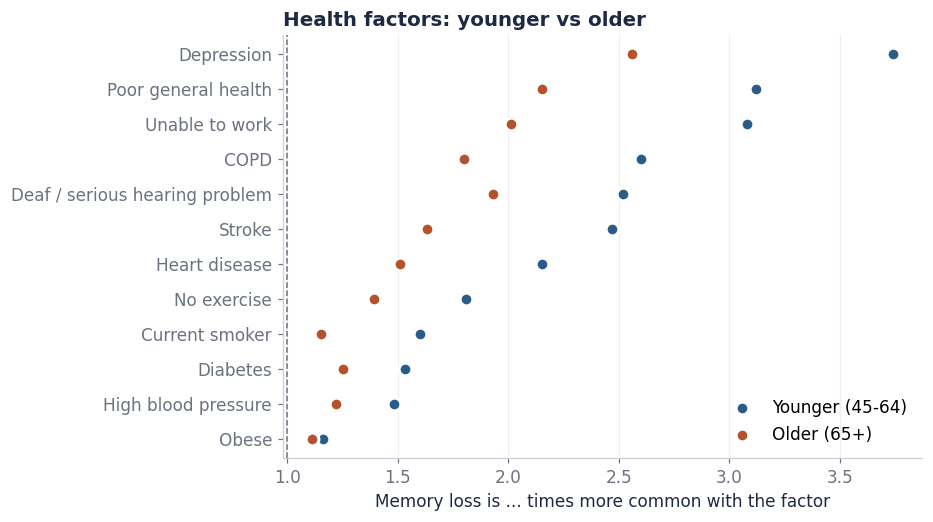

,factor,band,people_with,pct_with,pct_without,times_higher
0,Depression,Younger (45-64),22150,37.8,10.1,3.74
1,Depression,Older (65+),18528,35.5,13.8,2.56
2,Unable to work,Younger (45-64),10801,40.0,13.0,3.08
3,Unable to work,Older (65+),4644,32.8,16.3,2.01
4,Poor general health,Younger (45-64),20042,33.9,10.9,3.12
5,Poor general health,Older (65+),26707,28.4,13.2,2.15
6,Stroke,Younger (45-64),3680,37.6,15.2,2.47
7,Stroke,Older (65+),8863,26.7,16.4,1.63
8,Deaf / serious hearing problem,Younger (45-64),6230,37.0,14.7,2.52
9,Deaf / serious hearing problem,Older (65+),19647,28.7,14.9,1.93


In [5]:
factors = {"Depression": "depression", "Unable to work": "unable_to_work", "Poor general health": "poor_health",
           "Stroke": "stroke", "Deaf / serious hearing problem": "deaf", "COPD": "copd",
           "Heart disease": "heart_disease", "No exercise": "no_exercise", "Current smoker": "current_smoker",
           "Diabetes": "diabetes", "High blood pressure": "high_blood_pressure", "Obese": "obese"}
rows = []
for label, col in factors.items():
    for band in COLORS:
        d = df[(df["band"] == band)].dropna(subset=[col])
        w1, w0 = d[d[col] == 1], d[d[col] == 0]
        if min(len(w1), len(w0)) < MIN_GROUP:
            continue
        p1 = 100 * np.average(w1["memory_loss"], weights=w1["weight"])
        p0 = 100 * np.average(w0["memory_loss"], weights=w0["weight"])
        rows.append({"factor": label, "band": band, "people_with": len(w1),
                     "pct_with": round(p1, 1), "pct_without": round(p0, 1), "times_higher": round(p1 / p0, 2)})
health = pd.DataFrame(rows)

order = health[health["band"] == "Younger (45-64)"].sort_values("times_higher")["factor"].tolist()
fig, ax = plt.subplots(figsize=(7.5, 5))
for band, color in COLORS.items():
    d = health[health["band"] == band].set_index("factor").loc[order]
    ax.scatter(d["times_higher"], d.index, s=70, color=color, label=band, zorder=3, edgecolor="white", linewidth=2)
ax.axvline(1, color=MUTED, lw=1, ls="--")
ax.grid(axis="x", color="#ECEEF1"); ax.grid(axis="y", visible=False)
ax.set_xlabel("Memory loss is ... times more common with the factor")
ax.set_title("Health factors: younger vs older", loc="left")
ax.legend(frameon=False, loc="lower right")
save(fig, "04_health_factors"); plt.show()
health

## 5. Data quality

In [6]:
print("% missing per column:")
print((df.isna().mean() * 100).round(1).sort_values(ascending=False).head(8).to_string())
print("\nIncome missing (don't know / refused), weighted % memory loss:",
      round(100 * np.average(df.loc[df['income'].isna(), 'memory_loss'],
                             weights=df.loc[df['income'].isna(), 'weight']), 1))

% missing per column:
high_blood_pressure    37.1
income                 17.3
obese                   5.0
heart_disease           1.2
current_smoker          0.7
unable_to_work          0.6
copd                    0.5
deaf                    0.4

Income missing (don't know / refused), weighted % memory loss: 16.1


## What I see (first look, not final results)

- Memory loss is **almost as common at 50 (16.6%) as at 75 (17.4%)**; only 80+ is clearly higher (20.7%).
- **Income:** younger people with the lowest income report memory loss **4× more often** than the highest
  income (31.4% vs 8.1%); for older people about 1.5× (20.2% vs 13.5%).
- **Every health factor** goes with more memory loss, and the link is **stronger for younger people**.
  Strongest: depression, poor general health, unable to work, COPD, hearing problems, stroke.
- Careful: these factors are mixed together, and depression can affect how people judge their memory.

**Next step:** weighted logistic regression, younger vs older.